# 8.5 Advanced ML Statistics

**Goal:** understand probabilistic decisions, Bayesian optimization, shift, conformal intervals, and calibration.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Data Preprocessing](1_Data-Preprocessing.ipynb)
2. [Feature Engineering](2_Feature-Engineering.ipynb)
3. [Model Evaluation Statistics](3_Model-Evaluation-Statistics.ipynb)
4. [Statistical Learning Concepts](4_Statistical-Learning-Concepts.ipynb)
5. [Advanced ML Statistics](5_Advanced-ML-Statistics.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Probabilistic Classification and Bayesian Optimization

Probabilistic classification estimates P(Y|X), while a threshold maps that estimate into an action based on costs and constraints. Posterior normalization is not empirical calibration; a high-confidence score on unfamiliar inputs can be unreliable.

**Bayesian optimization** searches costly black-box objectives using a probabilistic surrogate and an acquisition rule balancing exploration/exploitation. A Gaussian process surrogate provides predictive mean/SD under kernel and noise assumptions; expected improvement and upper confidence bounds are examples of acquisition rules. Surrogate uncertainty is not a guarantee of global optimality or a substitute for honest final evaluation.

**Example:** a small noiseless GP interpolates five evaluations, then chooses the largest expected-improvement point over a finite candidate grid. Kernel and noise choices are fixed for illustration, not optimized or validated.

Next finite-grid EI candidate: 0.96


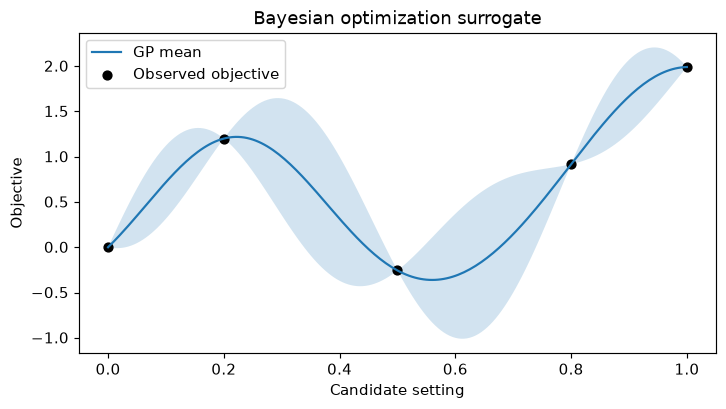

In [2]:
X=np.array([0.,.2,.5,.8,1.]);f=lambda x:np.sin(8*x)+x
observed=f(X);grid=np.linspace(0,1,201)
kernel=lambda a,b:np.exp(-.5*((a[:,None]-b[None,:])/.18)**2)
K=kernel(X,X)+1e-8*np.eye(len(X));cross=kernel(grid,X)
mean=cross@np.linalg.solve(K,observed)
variance=np.maximum(1-np.sum(cross*np.linalg.solve(K,cross.T).T,axis=1),0)
sd=np.sqrt(variance);improvement=mean-observed.max();z=improvement/np.maximum(sd,1e-12)
ei=improvement*stats.norm.cdf(z)+sd*stats.norm.pdf(z)
print("Next finite-grid EI candidate:",grid[np.argmax(ei)])
fig,ax=plt.subplots();ax.plot(grid,mean,label="GP mean");ax.fill_between(grid,mean-2*sd,mean+2*sd,alpha=.2)
ax.scatter(X,observed,color="black",label="Observed objective")
ax.set(title="Bayesian optimization surrogate",xlabel="Candidate setting",ylabel="Objective");ax.legend()
fig.tight_layout();plt.show()

## 2. Distribution Shift, Covariate Shift, Concept Drift, and Out-of-Distribution Detection

**Distribution shift** is any relevant change between source and target joint distributions. **Covariate shift** changes P(X) while P(Y|X) stays the same; importance weighting needs support overlap and stable conditional relationships. **Concept drift** changes the input-outcome relationship over time. Label/prior shift changes P(Y) while a model assumes P(X|Y) stable, another distinct hypothesis.

An **out-of-distribution (OOD)** detector scores unfamiliar inputs under a reference, using density, distance, learned representation, or other methods. Low density is not a universal anomaly score in high dimensions, and high classifier confidence does not guarantee in-distribution status. Evaluate detection on plausible shifts and known failure modes. Input monitoring alone cannot identify drift in P(Y|X) without labels or additional assumptions.

## 3. Conformal Prediction

Split conformal regression fits a predictor on training data, computes absolute residual scores on a separate calibration set, and uses the k-th order score with $k=\lceil(n_{cal}+1)(1-α)\rceil$. If k exceeds n_cal, the finite-sample conservative interval is unbounded rather than silently using the largest score. Output is $[\hat f(x)-q,\hat f(x)+q]$.

Under exchangeability of calibration and a new case and a fixed predictor independent of calibration labels, it has marginal coverage at least 1−α with the usual score/tie construction. This is not guaranteed conditional coverage for every input or subgroup, and ordinary exchangeability can fail in time series or distribution shift. Adaptive/specialized variants have different assumptions. Classification uses prediction sets rather than forcing the same numeric-interval formula.

In [3]:
x_train=rng.uniform(-2,2,100);y_train=1+2*x_train+rng.normal(size=100)
coef=np.linalg.lstsq(np.column_stack([np.ones(100),x_train]),y_train,rcond=None)[0]
xc=rng.uniform(-2,2,80);yc=1+2*xc+rng.normal(size=80)
cal_scores=np.abs(yc-(coef[0]+coef[1]*xc));alpha=.1;k=math.ceil((len(cal_scores)+1)*(1-alpha))
q=np.sort(cal_scores)[k-1] if k<=len(cal_scores) else np.inf
xt=rng.uniform(-2,2,5000);yt=1+2*xt+rng.normal(size=5000);prediction=coef[0]+coef[1]*xt
print("Calibration quantile:",q,"observed test coverage:",np.mean(np.abs(yt-prediction)<=q))

Calibration quantile: 1.4705990254120167 observed test coverage: 0.8532


## 4. Ensemble Uncertainty and Calibration Methods

An ensemble varies initialization, training samples, model structure, or posterior draws. Spread can reflect some sources of uncertainty but correlated models can confidently share errors; ensemble variance is not automatically a calibrated predictive interval.

Calibration methods include **Platt scaling** (logistic calibration of scores), **temperature scaling** (a positive scalar rescales logits), and **isotonic regression** (a nondecreasing fitted map). Flexible corrections need enough independent calibration data. Fit on a reserved calibration set and assess on different test data; fitting a map and judging its reliability on the same cases is optimistic.

**Example:** optimize a positive temperature using calibration log loss. A single temperature cannot fix every subgroup or nonmonotone miscalibration, and it cannot guarantee correction after shift.

In [4]:
logits=rng.normal(size=500)*2
labels=rng.binomial(1,special.expit(logits/2))
def temperature_nll(log_temperature):
    z=logits/np.exp(float(np.asarray(log_temperature).ravel()[0]))
    return np.mean(np.logaddexp(0,z)-labels*z)
cal_fit=optimize.minimize(temperature_nll,[0.])
temperature=np.exp(cal_fit.x[0])
print("Fitted temperature:",temperature,"calibration loss before/after:",temperature_nll([0.]),temperature_nll(cal_fit.x))
print("Independent test evaluation is required before claiming calibration improvement.")

Fitted temperature: 2.1022216962350964 calibration loss before/after: 0.6652931526874968 0.6003312190935858
Independent test evaluation is required before claiming calibration improvement.


## AI/ML application and interpretation

For production monitoring, track input coverage, label availability, subgroup error, calibration, and temporal changes alongside alerts. Recalibration, retraining, OOD rejection, and policy changes solve different problems. Validate the assumptions behind uncertainty guarantees after collection or deployment conditions change.

## Practice

1. Contrast covariate shift with concept drift.
2. Does 90% marginal conformal coverage guarantee 90% coverage in every subgroup?
3. Why use a calibration set distinct from training and final testing?
4. Can ensemble agreement prove a new input is familiar?
5. What does Bayesian optimization's acquisition function choose?

## Solutions

1. Covariate shift changes P(X) with fixed P(Y|X); drift can change the conditional relationship itself.
2. No. The guarantee averages over the target exchangeable distribution; subgroup/conditional guarantees need more.
3. It prevents using the same labels both to fit the correction and to judge it.
4. No. Shared architecture/data can cause confidently shared mistakes.
5. A candidate evaluation based on surrogate predictions and the selected exploration/exploitation objective, not a certified global optimum.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](../9-Expert-Level-Statistics-for-AI-Research/1_Information-Theory.ipynb).